In [1]:
# ==========================================
# FairXAI - Stage 3: Class Imbalance Experiment
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

RANDOM_STATE = 42

project_path = Path(r"D:\TY_Sem1\MLOps\FairXAi")

raw_path = project_path / "data" / "raw"
split_path = project_path / "data" / "split"
processed_path = project_path / "data" / "processed"
artifacts_path = project_path / "artifacts"

print("FairXAI - Stage 3: Class Imbalance Experiment")
print("=" * 55)

print(f"Project path: {project_path}")
print(f"Random state: {RANDOM_STATE}")

print("\nPaths:")
print(f"Raw data       : {raw_path}")
print(f"Split data     : {split_path}")
print(f"Processed data : {processed_path}")
print(f"Artifacts      : {artifacts_path}")

FairXAI - Stage 3: Class Imbalance Experiment
Project path: D:\TY_Sem1\MLOps\FairXAi
Random state: 42

Paths:
Raw data       : D:\TY_Sem1\MLOps\FairXAi\data\raw
Split data     : D:\TY_Sem1\MLOps\FairXAi\data\split
Processed data : D:\TY_Sem1\MLOps\FairXAi\data\processed
Artifacts      : D:\TY_Sem1\MLOps\FairXAi\artifacts


In [2]:
# ==========================================
# Cell 2: Load Stage 1 Train/Test Split
# ==========================================

target_column = "default payment next month"

train_path = split_path / "train.csv"
test_path = split_path / "test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nTarget distribution:")
print("Train:")
print(train_df[target_column].value_counts())
print("\nTest:")
print(test_df[target_column].value_counts())

print("\nTarget proportions:")
print("Train:")
print(train_df[target_column].value_counts(normalize=True))

print("\nTest:")
print(test_df[target_column].value_counts(normalize=True))

Train shape: (24000, 24)
Test shape : (6000, 24)

Train columns:
['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Test columns:
['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Target distribution:
Train:
default payment next month
0    18691
1     5309
Name: count, dtype: int64

Test:
default payment next month
0    4673
1    1327
Name: count, dtype: int64

Target proportions:
Train:
default payment next month
0    0.778792
1    0.221208
Name: proportion, dtype: float64

Test:
default payment next month
0    0.77883

In [3]:
# ==========================================
# Cell 3: Define Features and Target
# ==========================================

X_train = train_df.drop(columns=[target_column])
y_train = train_df[target_column]

X_test = test_df.drop(columns=[target_column])
y_test = test_df[target_column]

categorical_columns = [
    "SEX",
    "EDUCATION",
    "MARRIAGE"
]

ordinal_columns = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

continuous_columns = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

feature_columns = (
    categorical_columns
    + ordinal_columns
    + continuous_columns
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

print("\nFeature group sizes:")
print("Categorical :", len(categorical_columns))
print("Ordinal     :", len(ordinal_columns))
print("Continuous  :", len(continuous_columns))
print("Total       :", len(feature_columns))

print("\nAll feature columns match:", list(X_train.columns) == feature_columns)

X_train shape: (24000, 23)
y_train shape: (24000,)
X_test shape : (6000, 23)
y_test shape : (6000,)

Feature group sizes:
Categorical : 3
Ordinal     : 6
Continuous  : 14
Total       : 23

All feature columns match: True


In [4]:
# ==========================================
# Cell 4: Recreate Stage 1 Preprocessing
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

continuous_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_columns),
        ("continuous", continuous_transformer, continuous_columns)
    ],
    remainder="passthrough"
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the training-fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

processed_feature_names = preprocessor.get_feature_names_out()

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape    :", X_test_processed.shape)
print("Number of processed features:", len(processed_feature_names))

print("\nNaN check:")
print("Train:", np.isnan(X_train_processed).sum())
print("Test :", np.isnan(X_test_processed).sum())

print("\nInfinite value check:")
print("Train:", np.isinf(X_train_processed).sum())
print("Test :", np.isinf(X_test_processed).sum())

Processed training shape: (24000, 33)
Processed test shape    : (6000, 33)
Number of processed features: 33

NaN check:
Train: 0
Test : 0

Infinite value check:
Train: 0
Test : 0


In [6]:
# ==========================================
# Cell 5: Check Imbalanced-Learn
# ==========================================

try:
    import imblearn
    from imblearn.over_sampling import SMOTE
    
    print("imbalanced-learn is installed.")
    print("Version:", imblearn.__version__)

except ImportError:
    print("imbalanced-learn is NOT installed.")
    print("Install it with:")
    print("pip install imbalanced-learn")

imbalanced-learn is installed.
Version: 0.14.2


In [7]:
# ==========================================
# Cell 6: Define Imbalance Strategies
# ==========================================

from imblearn.over_sampling import SMOTENC

# Indices of categorical features in the ORIGINAL 23-feature dataset
categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_columns
]

print("Categorical feature indices:", categorical_indices)
print("Categorical features:", categorical_columns)

print("\nClass distribution before resampling:")
print(y_train.value_counts())

print("\nClass proportions:")
print(y_train.value_counts(normalize=True))

Categorical feature indices: [0, 1, 2]
Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE']

Class distribution before resampling:
default payment next month
0    18691
1     5309
Name: count, dtype: int64

Class proportions:
default payment next month
0    0.778792
1    0.221208
Name: proportion, dtype: float64


In [8]:
# ==========================================
# Cell 7: Apply SMOTENC to Training Data
# ==========================================

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=RANDOM_STATE
)

X_train_smote, y_train_smote = smotenc.fit_resample(
    X_train,
    y_train
)

print("Original training shape:", X_train.shape)
print("SMOTENC training shape :", X_train_smote.shape)

print("\nOriginal class distribution:")
print(y_train.value_counts())

print("\nSMOTENC class distribution:")
print(y_train_smote.value_counts())

print("\nSMOTENC class proportions:")
print(y_train_smote.value_counts(normalize=True))

Original training shape: (24000, 23)
SMOTENC training shape : (37382, 23)

Original class distribution:
default payment next month
0    18691
1     5309
Name: count, dtype: int64

SMOTENC class distribution:
default payment next month
0    18691
1    18691
Name: count, dtype: int64

SMOTENC class proportions:
default payment next month
0    0.5
1    0.5
Name: proportion, dtype: float64


In [9]:
# ==========================================
# Cell 8: Validate SMOTENC Categorical Values
# ==========================================

print("Unique categorical values after SMOTENC:\n")

for col in categorical_columns:
    original_values = sorted(X_train[col].unique())
    smote_values = sorted(X_train_smote[col].unique())

    print(f"{col}:")
    print("  Original:", original_values)
    print("  SMOTENC :", smote_values)
    print("  Valid   :", set(smote_values).issubset(set(original_values)))
    print()

Unique categorical values after SMOTENC:

SEX:
  Original: [np.int64(1), np.int64(2)]
  SMOTENC : [np.int64(1), np.int64(2)]
  Valid   : True

EDUCATION:
  Original: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
  SMOTENC : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
  Valid   : True

MARRIAGE:
  Original: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
  SMOTENC : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
  Valid   : True



In [10]:
# ==========================================
# Cell 9: Preprocess Original and SMOTENC Data
# ==========================================

# Original training data
X_train_original_processed = preprocessor.transform(X_train)

# SMOTENC training data
X_train_smote_processed = preprocessor.transform(X_train_smote)

# Test data - NEVER resampled
X_test_processed = preprocessor.transform(X_test)

print("Original processed train:", X_train_original_processed.shape)
print("SMOTENC processed train :", X_train_smote_processed.shape)
print("Processed test          :", X_test_processed.shape)

print("\nNaN check:")
print("Original:", np.isnan(X_train_original_processed).sum())
print("SMOTENC :", np.isnan(X_train_smote_processed).sum())
print("Test    :", np.isnan(X_test_processed).sum())

print("\nInfinite value check:")
print("Original:", np.isinf(X_train_original_processed).sum())
print("SMOTENC :", np.isinf(X_train_smote_processed).sum())
print("Test    :", np.isinf(X_test_processed).sum())

Original processed train: (24000, 33)
SMOTENC processed train : (37382, 33)
Processed test          : (6000, 33)

NaN check:
Original: 0
SMOTENC : 0
Test    : 0

Infinite value check:
Original: 0
SMOTENC : 0
Test    : 0


In [11]:
# ==========================================
# Cell 10: Define Stage 2 Models
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


models_original = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=21
    ),

    "Naive Bayes": GaussianNB(),

    "SVM": SVC(
        C=1,
        kernel="rbf",
        gamma="scale",
        probability=True,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=7,
        min_samples_leaf=10,
        min_samples_split=2,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=1.0,
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        n_jobs=-1
    )
}

print("Models defined:", len(models_original))
print()

for name, model in models_original.items():
    print(f"{name}:")
    print(f"  {model}")
    print()

Models defined: 7

Logistic Regression:
  LogisticRegression(max_iter=1000, random_state=42)

KNN:
  KNeighborsClassifier(n_neighbors=21)

Naive Bayes:
  GaussianNB()

SVM:
  SVC(C=1, probability=True, random_state=42)

Decision Tree:
  DecisionTreeClassifier(max_depth=7, min_samples_leaf=10, random_state=42)

Random Forest:
  RandomForestClassifier(max_depth=10, n_estimators=200, n_jobs=-1,
                       random_state=42)

XGBoost:
  XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=N

In [12]:
# ==========================================
# Cell 11: Define Class-Weighted Models
# ==========================================

models_class_weight = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "SVM": SVC(
        C=1,
        kernel="rbf",
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=7,
        min_samples_leaf=10,
        min_samples_split=2,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=1,
        max_features="sqrt",
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=1.0,
        scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]),
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        n_jobs=-1
    )
}

print("Class-weight models defined:", len(models_class_weight))
print()

for name, model in models_class_weight.items():
    print(f"{name}:")
    print(model)
    print()

Class-weight models defined: 5

Logistic Regression:
LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

SVM:
SVC(C=1, class_weight='balanced', probability=True, random_state=42)

Decision Tree:
DecisionTreeClassifier(class_weight='balanced', max_depth=7,
                       min_samples_leaf=10, random_state=42)

Random Forest:
RandomForestClassifier(class_weight='balanced', max_depth=10, n_estimators=200,
                       n_jobs=-1, random_state=42)

XGBoost:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, ma

In [13]:
# ==========================================
# Cell 12: Model Evaluation Function
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    balanced_accuracy_score,
    confusion_matrix
)


def evaluate_model(model, X_train_data, y_train_data,
                   X_test_data, y_test_data,
                   model_name, strategy):

    # Train
    model.fit(X_train_data, y_train_data)

    # Predictions
    y_pred = model.predict(X_test_data)

    # Probability estimates
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test_data)[:, 1]
    else:
        y_proba = None

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test_data,
        y_pred
    ).ravel()

    # Metrics
    accuracy = accuracy_score(y_test_data, y_pred)
    precision = precision_score(
        y_test_data, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test_data, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test_data, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test_data, y_proba
    )

    pr_auc = average_precision_score(
        y_test_data, y_proba
    )

    logloss = log_loss(
        y_test_data, y_proba
    )

    brier = brier_score_loss(
        y_test_data, y_proba
    )

    balanced_acc = balanced_accuracy_score(
        y_test_data, y_pred
    )

    fpr = fp / (fp + tn)
    fnr = fn / (fn + tp)

    return {
        "Model": model_name,
        "Strategy": strategy,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "Log Loss": logloss,
        "Brier": brier,
        "Balanced Accuracy": balanced_acc,
        "FPR": fpr,
        "FNR": fnr,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


print("Evaluation function created successfully.")

Evaluation function created successfully.


In [15]:
# ==========================================
# Cell 13A: Replace SVM With Calibrated SVM
# ==========================================

from sklearn.calibration import CalibratedClassifierCV

svm_base = SVC(
    C=1,
    kernel="rbf",
    gamma="scale",
    probability=False,
    random_state=RANDOM_STATE
)

svm_calibrated = CalibratedClassifierCV(
    estimator=svm_base,
    method="sigmoid",
    cv=3,
    n_jobs=-1
)

models_original["SVM"] = svm_calibrated

print("Updated SVM:")
print(models_original["SVM"])

Updated SVM:
CalibratedClassifierCV(cv=3,
                       estimator=SVC(C=1, probability=False, random_state=42),
                       n_jobs=-1)


In [16]:
# ==========================================
# Cell 13B: Train Original Models - Clean Run
# ==========================================

original_results = []

for model_name, model in models_original.items():

    print(f"Training: {model_name}")

    result = evaluate_model(
        model=model,
        X_train_data=X_train_original_processed,
        y_train_data=y_train,
        X_test_data=X_test_processed,
        y_test_data=y_test,
        model_name=model_name,
        strategy="Original"
    )

    original_results.append(result)

    print(
        f"  F1: {result['F1']:.4f} | "
        f"PR-AUC: {result['PR-AUC']:.4f} | "
        f"ROC-AUC: {result['ROC-AUC']:.4f}"
    )

original_results_df = pd.DataFrame(original_results)

print("\nOriginal strategy results:")
display(
    original_results_df[
        [
            "Model",
            "Strategy",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC",
            "Log Loss",
            "Brier",
            "Balanced Accuracy",
            "FPR",
            "FNR"
        ]
    ].round(4)
)

Training: Logistic Regression
  F1: 0.3610 | PR-AUC: 0.4949 | ROC-AUC: 0.7101
Training: KNN
  F1: 0.4428 | PR-AUC: 0.4920 | ROC-AUC: 0.7384
Training: Naive Bayes
  F1: 0.3773 | PR-AUC: 0.4610 | ROC-AUC: 0.7240
Training: SVM
  F1: 0.4357 | PR-AUC: 0.5101 | ROC-AUC: 0.7265
Training: Decision Tree
  F1: 0.4564 | PR-AUC: 0.5078 | ROC-AUC: 0.7488
Training: Random Forest
  F1: 0.4527 | PR-AUC: 0.5526 | ROC-AUC: 0.7736
Training: XGBoost
  F1: 0.4665 | PR-AUC: 0.5400 | ROC-AUC: 0.7712

Original strategy results:


,Model,Strategy,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss,Brier,Balanced Accuracy,FPR,FNR
0,Logistic Regression,Original,0.8088,0.6923,0.2442,0.3610,0.7101,0.4949,0.4704,0.1466,0.6067,0.0308,0.7558
1,KNN,Original,0.8092,0.6250,0.3429,0.4428,0.7384,0.4920,0.6574,0.1438,0.6422,0.0584,0.6571
2,Naive Bayes,Original,0.2913,0.2341,0.9706,0.3773,0.7240,0.4610,5.6964,0.6989,0.5345,0.9016,0.0294
3,SVM,Original,0.8165,0.6811,0.3203,0.4357,0.7265,0.5101,0.4582,0.1433,0.6388,0.0426,0.6797
4,Decision Tree,Original,0.8182,0.6735,0.3451,0.4564,0.7488,0.5078,0.5233,0.1398,0.6488,0.0475,0.6549
5,Random Forest,Original,0.8158,0.6604,0.3444,0.4527,0.7736,0.5526,0.4330,0.1360,0.6470,0.0503,0.6556
6,XGBoost,Original,0.8143,0.6399,0.3670,0.4665,0.7712,0.5400,0.4398,0.1379,0.6542,0.0586,0.6330


In [18]:
# ==========================================
# Cell 14A: Replace Class-Weighted SVM
# ==========================================

svm_class_weight_base = SVC(
    C=1,
    kernel="rbf",
    gamma="scale",
    class_weight="balanced",
    probability=False,
    random_state=RANDOM_STATE
)

svm_class_weight_calibrated = CalibratedClassifierCV(
    estimator=svm_class_weight_base,
    method="sigmoid",
    cv=3,
    n_jobs=-1
)

models_class_weight["SVM"] = svm_class_weight_calibrated

print("Updated class-weight SVM:")
print(models_class_weight["SVM"])

Updated class-weight SVM:
CalibratedClassifierCV(cv=3,
                       estimator=SVC(C=1, class_weight='balanced',
                                     probability=False, random_state=42),
                       n_jobs=-1)


In [19]:
# ==========================================
# Cell 14: Train Class-Weighted Models
# ==========================================

class_weight_results = []

for model_name, model in models_class_weight.items():

    print(f"Training: {model_name}")

    result = evaluate_model(
        model=model,
        X_train_data=X_train_original_processed,
        y_train_data=y_train,
        X_test_data=X_test_processed,
        y_test_data=y_test,
        model_name=model_name,
        strategy="Class Weight"
    )

    class_weight_results.append(result)

    print(
        f"  F1: {result['F1']:.4f} | "
        f"PR-AUC: {result['PR-AUC']:.4f} | "
        f"ROC-AUC: {result['ROC-AUC']:.4f}"
    )

class_weight_results_df = pd.DataFrame(class_weight_results)

print("\nClass Weight results:")
display(
    class_weight_results_df[
        [
            "Model",
            "Strategy",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC",
            "Log Loss",
            "Brier",
            "Balanced Accuracy",
            "FPR",
            "FNR"
        ]
    ].round(4)
)

Training: Logistic Regression
  F1: 0.4649 | PR-AUC: 0.4911 | ROC-AUC: 0.7106
Training: SVM
  F1: 0.4970 | PR-AUC: 0.4904 | ROC-AUC: 0.7530
Training: Decision Tree
  F1: 0.5130 | PR-AUC: 0.5133 | ROC-AUC: 0.7575
Training: Random Forest
  F1: 0.5379 | PR-AUC: 0.5513 | ROC-AUC: 0.7746
Training: XGBoost
  F1: 0.5203 | PR-AUC: 0.5425 | ROC-AUC: 0.7685

Class Weight results:


,Model,Strategy,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss,Brier,Balanced Accuracy,FPR,FNR
0,Logistic Regression,Class Weight,0.6782,0.3677,0.6323,0.4649,0.7106,0.4911,0.6073,0.2090,0.6617,0.3088,0.3677
1,SVM,Class Weight,0.8047,0.5773,0.4363,0.4970,0.7530,0.4904,0.4522,0.1429,0.6728,0.0907,0.5637
2,Decision Tree,Class Weight,0.7560,0.4592,0.5810,0.5130,0.7575,0.5133,0.6134,0.1866,0.6934,0.1943,0.4190
3,Random Forest,Class Weight,0.7767,0.4959,0.5878,0.5379,0.7746,0.5513,0.5397,0.1772,0.7090,0.1697,0.4122
4,XGBoost,Class Weight,0.7615,0.4686,0.5848,0.5203,0.7685,0.5425,0.5230,0.1714,0.6982,0.1883,0.4152


In [20]:
# ==========================================
# Cell 15: Define SMOTENC Models
# ==========================================

models_smote = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=21
    ),

    "Naive Bayes": GaussianNB(),

    "SVM": CalibratedClassifierCV(
        estimator=SVC(
            C=1,
            kernel="rbf",
            gamma="scale",
            probability=False,
            random_state=RANDOM_STATE
        ),
        method="sigmoid",
        cv=3,
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=7,
        min_samples_leaf=10,
        min_samples_split=2,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=1.0,
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        n_jobs=-1
    )
}

print("SMOTENC models defined:", len(models_smote))

for name in models_smote:
    print("-", name)

SMOTENC models defined: 7
- Logistic Regression
- KNN
- Naive Bayes
- SVM
- Decision Tree
- Random Forest
- XGBoost


In [21]:
# ==========================================
# Cell 16: Train SMOTENC Models
# ==========================================

smote_results = []

for model_name, model in models_smote.items():

    print(f"Training: {model_name}")

    result = evaluate_model(
        model=model,
        X_train_data=X_train_smote_processed,
        y_train_data=y_train_smote,
        X_test_data=X_test_processed,
        y_test_data=y_test,
        model_name=model_name,
        strategy="SMOTENC"
    )

    smote_results.append(result)

    print(
        f"  F1: {result['F1']:.4f} | "
        f"PR-AUC: {result['PR-AUC']:.4f} | "
        f"ROC-AUC: {result['ROC-AUC']:.4f}"
    )

smote_results_df = pd.DataFrame(smote_results)

print("\nSMOTENC results:")

display(
    smote_results_df[
        [
            "Model",
            "Strategy",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC",
            "Log Loss",
            "Brier",
            "Balanced Accuracy",
            "FPR",
            "FNR"
        ]
    ].round(4)
)

Training: Logistic Regression
  F1: 0.4525 | PR-AUC: 0.4973 | ROC-AUC: 0.7106
Training: KNN
  F1: 0.4731 | PR-AUC: 0.4656 | ROC-AUC: 0.7267
Training: Naive Bayes
  F1: 0.3761 | PR-AUC: 0.4725 | ROC-AUC: 0.6997
Training: SVM
  F1: 0.4914 | PR-AUC: 0.4898 | ROC-AUC: 0.7382
Training: Decision Tree
  F1: 0.4851 | PR-AUC: 0.4616 | ROC-AUC: 0.7216
Training: Random Forest
  F1: 0.5235 | PR-AUC: 0.5269 | ROC-AUC: 0.7622
Training: XGBoost
  F1: 0.4894 | PR-AUC: 0.5054 | ROC-AUC: 0.7422

SMOTENC results:


,Model,Strategy,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss,Brier,Balanced Accuracy,FPR,FNR
0,Logistic Regression,SMOTENC,0.6555,0.3489,0.6436,0.4525,0.7106,0.4973,0.6111,0.2108,0.6512,0.3411,0.3564
1,KNN,SMOTENC,0.7048,0.3909,0.5991,0.4731,0.7267,0.4656,0.6655,0.1960,0.6670,0.2651,0.4009
2,Naive Bayes,SMOTENC,0.2933,0.2337,0.9631,0.3761,0.6997,0.4725,9.3232,0.7032,0.5331,0.8969,0.0369
3,SVM,SMOTENC,0.7185,0.4092,0.6149,0.4914,0.7382,0.4898,0.5708,0.1928,0.6814,0.2521,0.3851
4,Decision Tree,SMOTENC,0.7810,0.5053,0.4665,0.4851,0.7216,0.4616,0.5729,0.1814,0.6684,0.1297,0.5335
5,Random Forest,SMOTENC,0.7825,0.5078,0.5403,0.5235,0.7622,0.5269,0.5236,0.1708,0.6958,0.1487,0.4597
6,XGBoost,SMOTENC,0.7792,0.5008,0.4785,0.4894,0.7422,0.5054,0.4927,0.1597,0.6715,0.1355,0.5215


In [22]:
# ==========================================
# Cell 17: Combine All Stage 3 Results
# ==========================================

stage3_results = pd.concat(
    [
        original_results_df,
        class_weight_results_df,
        smote_results_df
    ],
    ignore_index=True
)

stage3_results = stage3_results[
    [
        "Model",
        "Strategy",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC",
        "Log Loss",
        "Brier",
        "Balanced Accuracy",
        "FPR",
        "FNR",
        "TN",
        "FP",
        "FN",
        "TP"
    ]
]

print("Stage 3 result shape:", stage3_results.shape)

display(
    stage3_results.round(4)
)

Stage 3 result shape: (19, 17)


,Model,Strategy,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss,Brier,Balanced Accuracy,FPR,FNR,TN,FP,FN,TP
0,Logistic Regression,Original,0.8088,0.6923,0.2442,0.3610,0.7101,0.4949,0.4704,0.1466,0.6067,0.0308,0.7558,4529,144,1003,324
1,KNN,Original,0.8092,0.6250,0.3429,0.4428,0.7384,0.4920,0.6574,0.1438,0.6422,0.0584,0.6571,4400,273,872,455
2,Naive Bayes,Original,0.2913,0.2341,0.9706,0.3773,0.7240,0.4610,5.6964,0.6989,0.5345,0.9016,0.0294,460,4213,39,1288
3,SVM,Original,0.8165,0.6811,0.3203,0.4357,0.7265,0.5101,0.4582,0.1433,0.6388,0.0426,0.6797,4474,199,902,425
4,Decision Tree,Original,0.8182,0.6735,0.3451,0.4564,0.7488,0.5078,0.5233,0.1398,0.6488,0.0475,0.6549,4451,222,869,458
5,Random Forest,Original,0.8158,0.6604,0.3444,0.4527,0.7736,0.5526,0.4330,0.1360,0.6470,0.0503,0.6556,4438,235,870,457
6,XGBoost,Original,0.8143,0.6399,0.3670,0.4665,0.7712,0.5400,0.4398,0.1379,0.6542,0.0586,0.6330,4399,274,840,487
7,Logistic Regression,Class Weight,0.6782,0.3677,0.6323,0.4649,0.7106,0.4911,0.6073,0.2090,0.6617,0.3088,0.3677,3230,1443,488,839
8,SVM,Class Weight,0.8047,0.5773,0.4363,0.4970,0.7530,0.4904,0.4522,0.1429,0.6728,0.0907,0.5637,4249,424,748,579
9,Decision Tree,Class Weight,0.7560,0.4592,0.5810,0.5130,0.7575,0.5133,0.6134,0.1866,0.6934,0.1943,0.4190,3765,908,556,771


In [23]:
# ==========================================
# Cell 18: Prepare Stage 3 Comparison Data
# ==========================================

comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC",
    "Log Loss",
    "Brier",
    "Balanced Accuracy",
    "FPR",
    "FNR"
]

print("Available models:")
print(stage3_results["Model"].unique())

print("\nAvailable strategies:")
print(stage3_results["Strategy"].unique())

print("\nResults per strategy:")
print(stage3_results["Strategy"].value_counts())

print("\nMean metrics by strategy:")
display(
    stage3_results.groupby("Strategy")[comparison_metrics]
    .mean()
    .round(4)
)

Available models:
<ArrowStringArray>
['Logistic Regression',                 'KNN',         'Naive Bayes',
                 'SVM',       'Decision Tree',       'Random Forest',
             'XGBoost']
Length: 7, dtype: str

Available strategies:
<ArrowStringArray>
['Original', 'Class Weight', 'SMOTENC']
Length: 3, dtype: str

Results per strategy:
Strategy
Original        7
SMOTENC         7
Class Weight    5
Name: count, dtype: int64

Mean metrics by strategy:


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Log Loss,Brier,Balanced Accuracy,FPR,FNR
Strategy,,,,,,,,,,,
Class Weight,0.7554,0.4737,0.5644,0.5066,0.7528,0.5177,0.5471,0.1774,0.6870,0.1904,0.4356
Original,0.7392,0.6009,0.4192,0.4275,0.7418,0.5084,1.2398,0.2209,0.6246,0.1700,0.5808
SMOTENC,0.6735,0.4138,0.6151,0.4702,0.7287,0.4884,1.8228,0.2592,0.6526,0.3099,0.3849


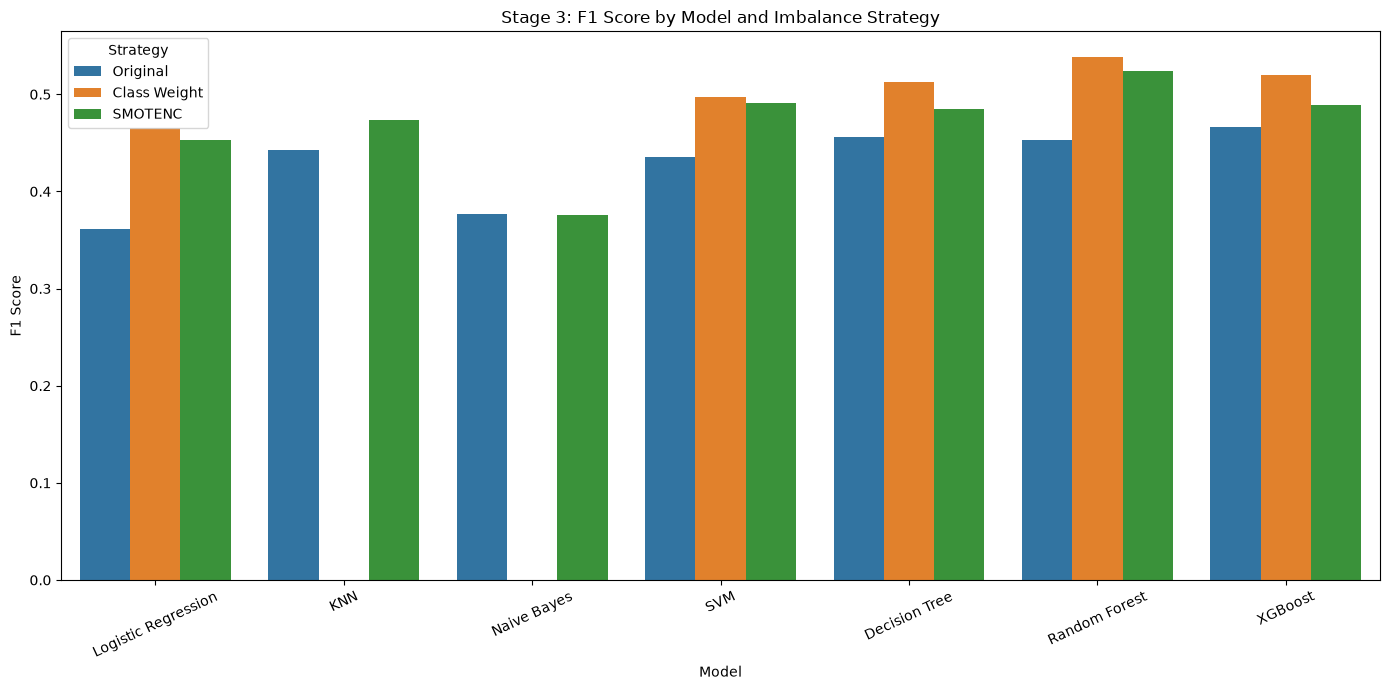

In [24]:
# ==========================================
# Cell 19: F1 Comparison
# ==========================================

plt.figure(figsize=(14, 7))

sns.barplot(
    data=stage3_results,
    x="Model",
    y="F1",
    hue="Strategy"
)

plt.title("Stage 3: F1 Score by Model and Imbalance Strategy")
plt.xlabel("Model")
plt.ylabel("F1 Score")
plt.xticks(rotation=25)
plt.legend(title="Strategy")
plt.tight_layout()
plt.show()

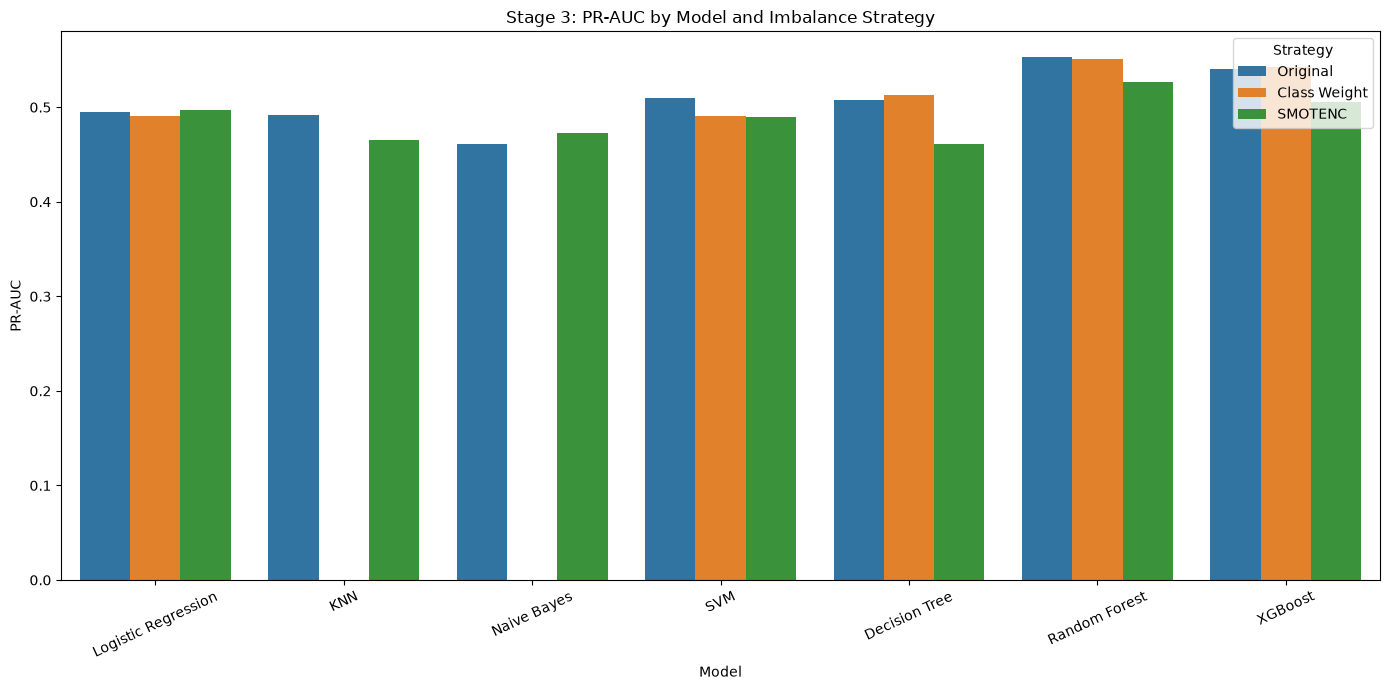

In [25]:
# ==========================================
# Cell 20: PR-AUC Comparison
# ==========================================

plt.figure(figsize=(14, 7))

sns.barplot(
    data=stage3_results,
    x="Model",
    y="PR-AUC",
    hue="Strategy"
)

plt.title("Stage 3: PR-AUC by Model and Imbalance Strategy")
plt.xlabel("Model")
plt.ylabel("PR-AUC")
plt.xticks(rotation=25)
plt.legend(title="Strategy")
plt.tight_layout()
plt.show()

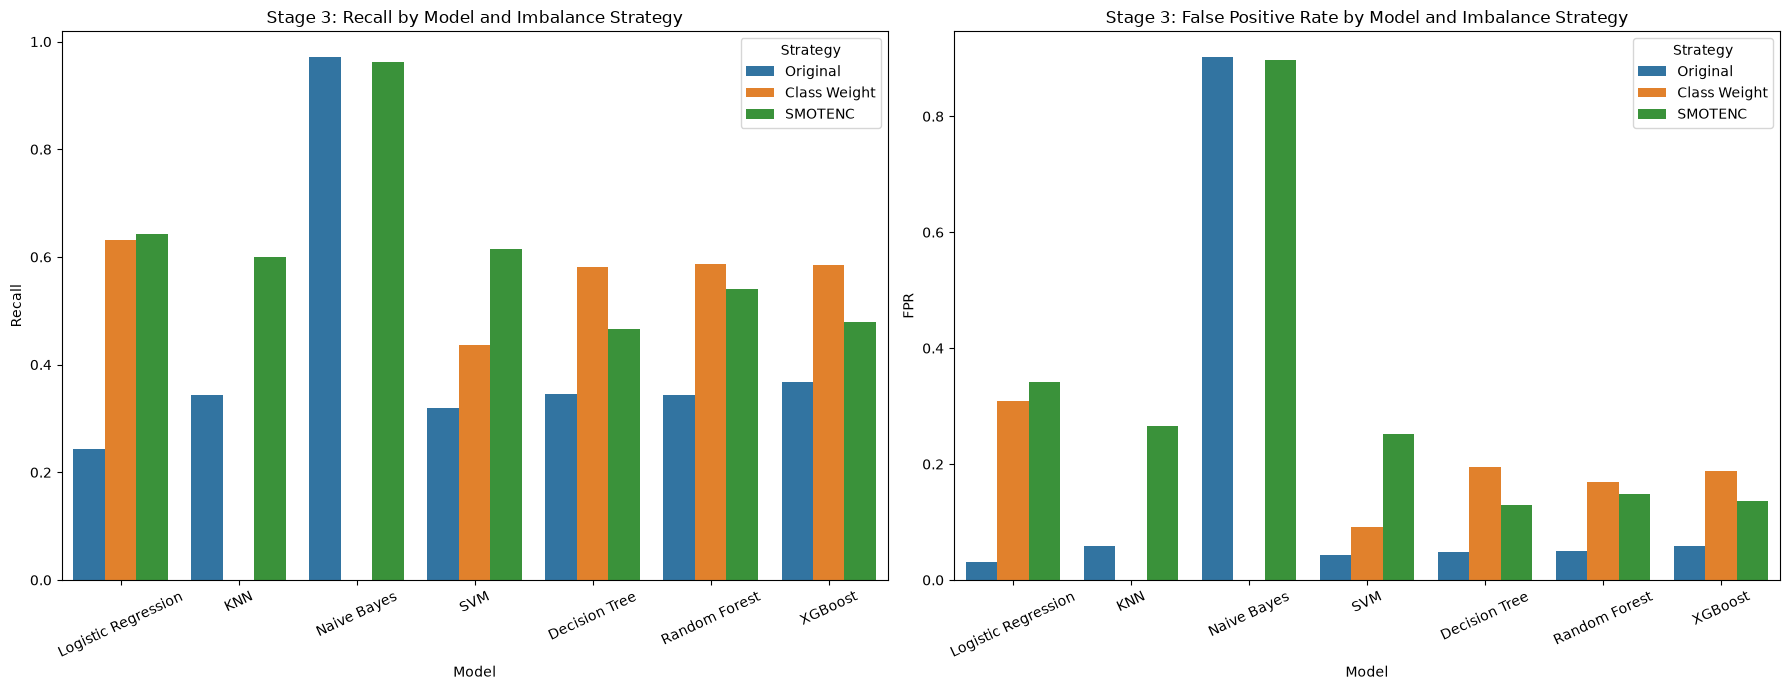

In [27]:
# ==========================================
# Cell 21: Recall and FPR Comparison
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# -----------------------------
# Recall
# -----------------------------
sns.barplot(
    data=stage3_results,
    x="Model",
    y="Recall",
    hue="Strategy",
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Stage 3: Recall by Model and Imbalance Strategy")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Recall")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(title="Strategy")


# -----------------------------
# FPR
# -----------------------------
sns.barplot(
    data=stage3_results,
    x="Model",
    y="FPR",
    hue="Strategy",
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Stage 3: False Positive Rate by Model and Imbalance Strategy")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("FPR")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(title="Strategy")

plt.tight_layout()
plt.show()

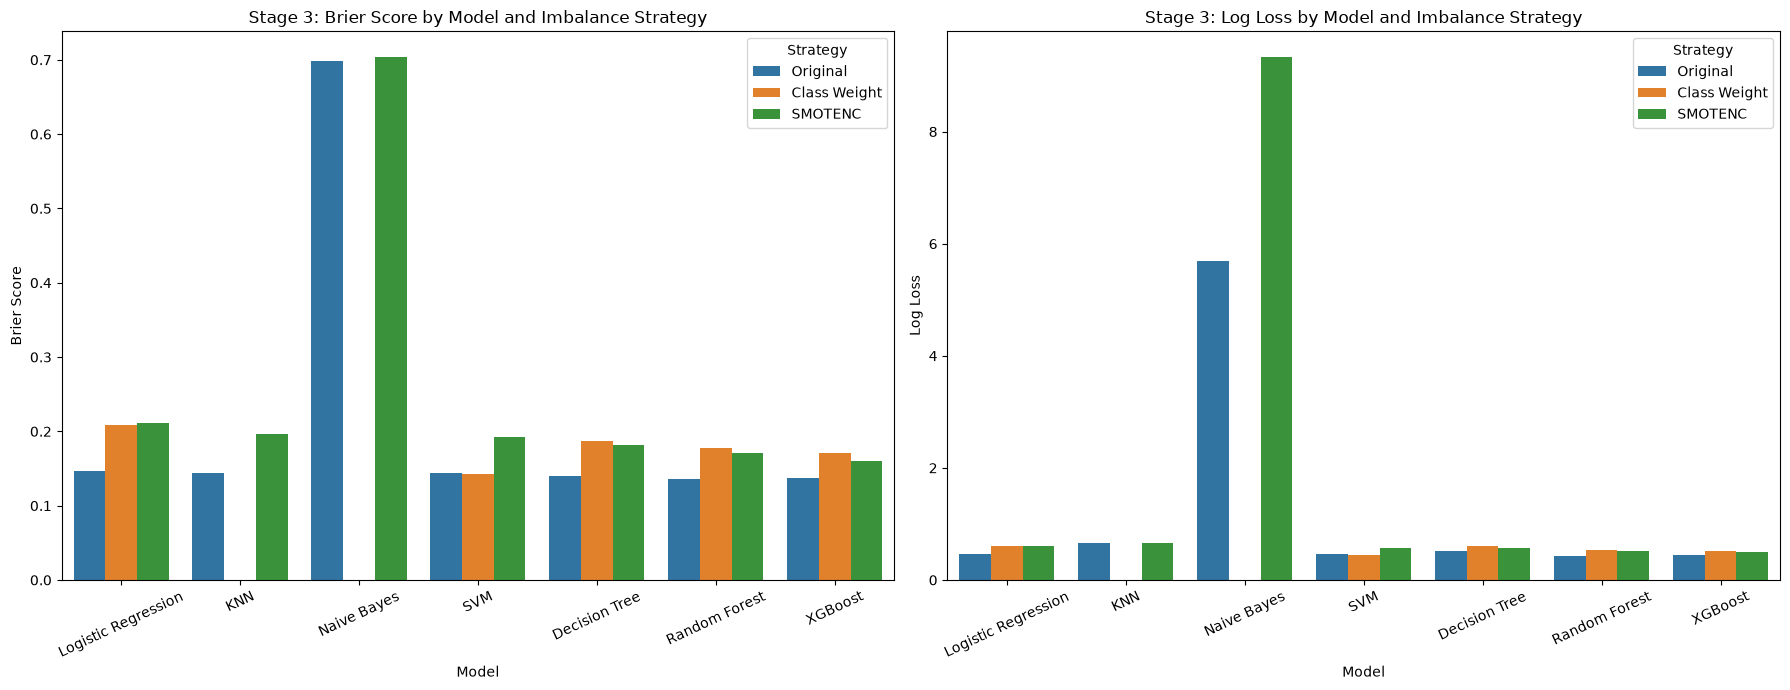

In [28]:
# ==========================================
# Cell 22: Calibration Comparison
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# -----------------------------
# Brier Score
# -----------------------------
sns.barplot(
    data=stage3_results,
    x="Model",
    y="Brier",
    hue="Strategy",
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Stage 3: Brier Score by Model and Imbalance Strategy")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Brier Score")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(title="Strategy")


# -----------------------------
# Log Loss
# -----------------------------
sns.barplot(
    data=stage3_results,
    x="Model",
    y="Log Loss",
    hue="Strategy",
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Stage 3: Log Loss by Model and Imbalance Strategy")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Log Loss")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(title="Strategy")

plt.tight_layout()
plt.show()

In [29]:
# ==========================================
# Cell 23: Strategy Change Relative to Original
# ==========================================

original_reference = (
    stage3_results[stage3_results["Strategy"] == "Original"]
    .set_index("Model")
)

strategy_changes = stage3_results[
    stage3_results["Strategy"] != "Original"
].copy()

for metric in ["F1", "PR-AUC", "Recall", "FPR", "Brier", "Log Loss"]:
    strategy_changes[f"{metric} Change"] = (
        strategy_changes.apply(
            lambda row: row[metric] - original_reference.loc[row["Model"], metric],
            axis=1
        )
    )

display(
    strategy_changes[
        [
            "Model",
            "Strategy",
            "F1 Change",
            "PR-AUC Change",
            "Recall Change",
            "FPR Change",
            "Brier Change",
            "Log Loss Change"
        ]
    ].round(4)
)

,Model,Strategy,F1 Change,PR-AUC Change,Recall Change,FPR Change,Brier Change,Log Loss Change
7,Logistic Regression,Class Weight,0.1039,-0.0038,0.3881,0.2780,0.0624,0.1369
8,SVM,Class Weight,0.0613,-0.0197,0.1161,0.0481,-0.0005,-0.0059
9,Decision Tree,Class Weight,0.0566,0.0055,0.2359,0.1468,0.0468,0.0900
10,Random Forest,Class Weight,0.0852,-0.0014,0.2434,0.1194,0.0413,0.1067
11,XGBoost,Class Weight,0.0538,0.0025,0.2178,0.1297,0.0336,0.0832
12,Logistic Regression,SMOTENC,0.0914,0.0024,0.3994,0.3103,0.0642,0.1407
13,KNN,SMOTENC,0.0303,-0.0264,0.2562,0.2067,0.0522,0.0080
14,Naive Bayes,SMOTENC,-0.0012,0.0115,-0.0075,-0.0047,0.0043,3.6268
15,SVM,SMOTENC,0.0557,-0.0204,0.2946,0.2095,0.0494,0.1127
16,Decision Tree,SMOTENC,0.0287,-0.0462,0.1213,0.0822,0.0416,0.0496


In [30]:
# ==========================================
# Cell 24: Stage 3 Summary Table
# ==========================================

summary_metrics = [
    "Accuracy",
    "Recall",
    "F1",
    "PR-AUC",
    "ROC-AUC",
    "Brier",
    "Log Loss",
    "FPR",
    "FNR"
]

stage3_summary = (
    stage3_results
    .groupby("Strategy")[summary_metrics]
    .mean()
    .round(4)
)

display(stage3_summary)

,Accuracy,Recall,F1,PR-AUC,ROC-AUC,Brier,Log Loss,FPR,FNR
Strategy,,,,,,,,,
Class Weight,0.7554,0.5644,0.5066,0.5177,0.7528,0.1774,0.5471,0.1904,0.4356
Original,0.7392,0.4192,0.4275,0.5084,0.7418,0.2209,1.2398,0.1700,0.5808
SMOTENC,0.6735,0.6151,0.4702,0.4884,0.7287,0.2592,1.8228,0.3099,0.3849


In [31]:
# ==========================================
# Cell 25: Model-wise Strategy Comparison
# ==========================================

stage3_model_comparison = stage3_results[
    ["Model", "Strategy", "F1", "PR-AUC", "Recall", "FPR", "FNR", "Brier", "Log Loss"]
].copy()

stage3_model_comparison = stage3_model_comparison.sort_values(
    ["Model", "Strategy"]
)

display(
    stage3_model_comparison.round(4)
)

,Model,Strategy,F1,PR-AUC,Recall,FPR,FNR,Brier,Log Loss
9,Decision Tree,Class Weight,0.5130,0.5133,0.5810,0.1943,0.4190,0.1866,0.6134
4,Decision Tree,Original,0.4564,0.5078,0.3451,0.0475,0.6549,0.1398,0.5233
16,Decision Tree,SMOTENC,0.4851,0.4616,0.4665,0.1297,0.5335,0.1814,0.5729
1,KNN,Original,0.4428,0.4920,0.3429,0.0584,0.6571,0.1438,0.6574
13,KNN,SMOTENC,0.4731,0.4656,0.5991,0.2651,0.4009,0.1960,0.6655
7,Logistic Regression,Class Weight,0.4649,0.4911,0.6323,0.3088,0.3677,0.2090,0.6073
0,Logistic Regression,Original,0.3610,0.4949,0.2442,0.0308,0.7558,0.1466,0.4704
12,Logistic Regression,SMOTENC,0.4525,0.4973,0.6436,0.3411,0.3564,0.2108,0.6111
2,Naive Bayes,Original,0.3773,0.4610,0.9706,0.9016,0.0294,0.6989,5.6964
14,Naive Bayes,SMOTENC,0.3761,0.4725,0.9631,0.8969,0.0369,0.7032,9.3232


In [32]:
# ==========================================
# Final Cell: Save All Stage 3 Artifacts
# ==========================================

import json

# ------------------------------------------
# 1. Create output directories
# ------------------------------------------

results_path = project_path / "data" / "results"
smote_path = project_path / "data" / "smote"

results_path.mkdir(parents=True, exist_ok=True)
smote_path.mkdir(parents=True, exist_ok=True)


# ------------------------------------------
# 2. Save complete Stage 3 results
# ------------------------------------------

stage3_results_path = results_path / "stage3_model_results.csv"

stage3_results.to_csv(
    stage3_results_path,
    index=False
)


# ------------------------------------------
# 3. Save strategy changes
# ------------------------------------------

strategy_changes_path = results_path / "stage3_strategy_changes.csv"

strategy_changes[
    [
        "Model",
        "Strategy",
        "F1 Change",
        "PR-AUC Change",
        "Recall Change",
        "FPR Change",
        "Brier Change",
        "Log Loss Change"
    ]
].to_csv(
    strategy_changes_path,
    index=False
)


# ------------------------------------------
# 4. Save SMOTENC training dataset
# ------------------------------------------

smote_train = X_train_smote.copy()

smote_train[target_column] = (
    y_train_smote.reset_index(drop=True)
)

smote_train_path = smote_path / "train_smote.csv"

smote_train.to_csv(
    smote_train_path,
    index=False
)


# ------------------------------------------
# 5. Save SMOTENC metadata
# ------------------------------------------

smote_metadata = {
    "method": "SMOTENC",
    "random_state": RANDOM_STATE,
    "original_training_rows": int(len(X_train)),
    "smote_training_rows": int(len(X_train_smote)),
    "synthetic_rows_added": int(len(X_train_smote) - len(X_train)),
    "original_class_distribution": {
        str(k): int(v)
        for k, v in y_train.value_counts().to_dict().items()
    },
    "smote_class_distribution": {
        str(k): int(v)
        for k, v in y_train_smote.value_counts().to_dict().items()
    },
    "categorical_columns": categorical_columns,
    "categorical_indices": categorical_indices
}

smote_metadata_path = smote_path / "smote_metadata.json"

with open(smote_metadata_path, "w") as f:
    json.dump(smote_metadata, f, indent=4)


# ------------------------------------------
# 6. Print everything saved
# ------------------------------------------

print("=" * 60)
print("STAGE 3 ARTIFACTS SAVED SUCCESSFULLY")
print("=" * 60)

print("\n1. Model Results:")
print(stage3_results_path)

print("\n2. Strategy Changes:")
print(strategy_changes_path)

print("\n3. SMOTENC Training Data:")
print(smote_train_path)

print("\n4. SMOTENC Metadata:")
print(smote_metadata_path)

print("\nShapes:")
print(f"Stage 3 results       : {stage3_results.shape}")
print(f"Strategy changes      : {strategy_changes.shape}")
print(f"SMOTENC training data : {smote_train.shape}")

print("\nSMOTENC class distribution:")
print(smote_train[target_column].value_counts())

print("\nAll Stage 3 artifacts are ready.")

STAGE 3 ARTIFACTS SAVED SUCCESSFULLY

1. Model Results:
D:\TY_Sem1\MLOps\FairXAi\data\results\stage3_model_results.csv

2. Strategy Changes:
D:\TY_Sem1\MLOps\FairXAi\data\results\stage3_strategy_changes.csv

3. SMOTENC Training Data:
D:\TY_Sem1\MLOps\FairXAi\data\smote\train_smote.csv

4. SMOTENC Metadata:
D:\TY_Sem1\MLOps\FairXAi\data\smote\smote_metadata.json

Shapes:
Stage 3 results       : (19, 17)
Strategy changes      : (12, 23)
SMOTENC training data : (37382, 24)

SMOTENC class distribution:
default payment next month
0    18691
1    18691
Name: count, dtype: int64

All Stage 3 artifacts are ready.


In [ ]:
### Key Findings

#### 1. Effect of Class Weighting Compared with Original Training

Compared with the Original strategy, Class Weighting produced the following general changes across the models where class weighting was applicable:

**Metrics that generally increased:**
- Recall increased substantially.
- F1 Score increased for every model tested with Class Weighting.
- Balanced Accuracy increased.
- False Positive Rate (FPR) increased.
- Consequently, the number of false-positive predictions increased.

**Metrics that generally decreased:**
- False Negative Rate (FNR) decreased substantially.
- Brier Score generally increased, indicating worse probability calibration because lower Brier Score is better.
- Log Loss generally increased, also indicating worse probability quality.
- Accuracy generally decreased because the models classified more observations as positive/default.

**Metrics with relatively small or mixed changes:**
- PR-AUC changed only slightly overall; it increased for some models and decreased for others.
- ROC-AUC also showed relatively small changes and was model-dependent.

Overall, Class Weighting shifted the models toward detecting more positive/default cases. This increased Recall and F1 but also increased FPR and generally reduced probability calibration quality.

---

#### 2. Effect of SMOTENC Compared with Original Training

Compared with the Original strategy, SMOTENC produced the following general changes:

**Metrics that generally increased:**
- Recall increased for most models.
- F1 Score increased for most models.
- Balanced Accuracy generally increased.
- False Positive Rate increased.
- Consequently, more non-default observations were classified as default.

**Metrics that generally decreased:**
- False Negative Rate (FNR) decreased substantially for most models.
- PR-AUC decreased for several models, particularly the tree-based models.
- ROC-AUC generally decreased for several models.
- Probability calibration generally worsened, reflected by increases in Brier Score and Log Loss.

**Metrics with model-dependent behavior:**
- PR-AUC increased slightly for Logistic Regression and Naive Bayes but decreased for KNN, SVM, Decision Tree, Random Forest, and XGBoost.
- ROC-AUC also varied by model rather than changing consistently in one direction.
- Accuracy generally decreased.

Overall, SMOTENC shifted the models toward detecting more positive/default cases, increasing Recall and generally reducing FNR. However, this came with higher FPR and, for several models, reduced ranking performance and worse probability calibration.

---

#### 3. Direct Comparison of the Two Imbalance Strategies

Both Class Weighting and SMOTENC produced a similar broad effect:

**More defaults detected → higher Recall and lower FNR → more false positives → higher FPR.**

However, their effects on ranking and probability quality differed:

- Class Weighting generally produced larger and more consistent F1 improvements.
- Class Weighting generally preserved PR-AUC closer to the Original strategy.
- SMOTENC produced the highest average Recall but also the highest average FPR.
- SMOTENC caused larger PR-AUC reductions for several tree-based models.
- Both strategies generally worsened Brier Score and Log Loss compared with Original training.

Therefore, neither imbalance strategy can be considered universally superior based on the predictive metrics alone.